# DriftWise: real-data experiments (UNSW-NB15)
Requires `UNSW_NB15_DriftWise_clean_chronological.csv.gz` in `MyDrive/DriftWise/data/processed/` (made by the preprocessing notebook).

**Order:** 1) install, restart; 2) setup; 3) the rest, in order. Nothing is shuffled and no drift is injected: we study the drift that is naturally in the data.

## 1. Install packages (run once, then Runtime > Restart session)

In [1]:
!pip install river "numpy<2.3" -q

In [1]:
import numpy, sklearn, river
print("numpy", numpy.__version__, "| sklearn", sklearn.__version__, "| river", river.__version__)

numpy 2.2.6 | sklearn 1.6.1 | river 0.26.1


## 2. Setup: load data, build features, train the frozen model
The model is trained once on the first slice of the active window (rows 0 to 17,343) and never updated. Categories, scaler and model all come from that slice only.

In [2]:
import os
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import recall_score, balanced_accuracy_score
drive.mount("/content/drive")

path = "/content/drive/MyDrive/DriftWise/data/processed/UNSW_NB15_DriftWise_clean_chronological.csv.gz"
df = pd.read_csv(path, low_memory=False)
for c in ["sport", "dsport"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

drop_cols = ["Label", "attack_cat", "srcip", "dstip", "Stime", "Ltime", "Stime_UTC", "Ltime_UTC"]
cat_cols = ["proto", "state", "service"]
num_cols = [c for c in df.columns if c not in drop_cols + cat_cols]
print("Features:", len(num_cols), "numeric +", len(cat_cols), "categorical =", len(num_cols) + len(cat_cols))

train_end = 17344                     # the first slice of the active window
train = df.iloc[:train_end]
keep = {c: set(train[c].value_counts().head(10 if c == "proto" else 50).index) for c in cat_cols}

def make_features(d):
    num = d[num_cols].fillna(-1).astype(float)
    num = np.sign(num) * np.log1p(np.abs(num))            # tame very large values
    cats = d[cat_cols].copy()
    for c in cat_cols:
        cats[c] = cats[c].where(cats[c].isin(keep[c]), "other")
    return pd.concat([num, pd.get_dummies(cats, dtype=float)], axis=1)

X_train = make_features(train)
columns = X_train.columns
scaler = StandardScaler().fit(X_train)
model = SGDClassifier(loss="log_loss", class_weight="balanced", random_state=42)
model.fit(scaler.transform(X_train), train["Label"])
print("Model columns:", len(columns), "| trained on the first", train_end, "rows")

def predict_rows(d):
    X = make_features(d).reindex(columns=columns, fill_value=0.0)
    return model.predict(scaler.transform(X))

last_attack = int(np.where(df["Label"].values == 1)[0].max())

# Predictions of the frozen model on every row after the training slice
y_full = df["Label"].to_numpy()
preds = np.concatenate([predict_rows(df.iloc[a:a + 50000]) for a in range(train_end, len(df), 50000)])
y = y_full[train_end:]
idx = np.arange(train_end, len(df))
errors = (preds != y).astype(int)       # 1 = the frozen model made a mistake on that row
print("Setup done. Active window ends at row", last_attack)

Mounted at /content/drive
Features: 40 numeric + 3 categorical = 43
Model columns: 64 | trained on the first 17344 rows
Setup done. Active window ends at row 173432


## 3. Frozen model: how does it do block by block?
Blocks of 5,000 rows in the active window and 50,000 rows in the normal-only tail.

In [3]:
blocks = [(s, min(s + 5000, last_attack + 1)) for s in range(train_end, last_attack + 1, 5000)]
blocks += [(s, min(s + 50000, len(df))) for s in range(last_attack + 1, len(df), 50000)]

rows = []
for a, b in blocks:
    yb = y_full[a:b]
    pb = preds[a - train_end:b - train_end]
    n_att = int(yb.sum())
    rows.append({
        "rows": f"{a}-{b - 1}",
        "region": "active" if b <= last_attack + 1 else "normal-only tail",
        "attacks": n_att,
        "attack_rate_%": round(100 * n_att / len(yb), 1),
        "attack_recall": round(recall_score(yb, pb, pos_label=1), 3) if n_att > 0 else np.nan,
        "normal_recall": round(recall_score(yb, pb, pos_label=0), 3),
        "balanced_acc": round(balanced_accuracy_score(yb, pb), 3) if n_att > 0 else np.nan,
    })
res_blocks = pd.DataFrame(rows)
pd.set_option("display.width", 250, "display.max_rows", 100, "display.max_columns", 20)
display(res_blocks)

,rows,region,attacks,attack_rate_%,attack_recall,normal_recall,balanced_acc
0,17344-22343,active,254,5.1,0.965,0.949,0.957
1,22344-27343,active,432,8.6,0.979,0.981,0.980
2,27344-32343,active,316,6.3,0.978,0.858,0.918
3,32344-37343,active,406,8.1,0.970,0.919,0.945
4,37344-42343,active,246,4.9,0.980,0.986,0.983
5,42344-47343,active,303,6.1,0.997,0.993,0.995
6,47344-52343,active,275,5.5,0.982,0.999,0.990
7,52344-57343,active,296,5.9,0.997,0.996,0.996
8,57344-62343,active,272,5.4,1.000,0.990,0.995
9,62344-67343,active,252,5.0,0.976,0.965,0.971


## 4. ADWIN on the overall error rate
Note: ADWIN fires on a rise *and* on a fall of the error rate, and the overall error is dominated by normal traffic.

Total alarms: 38
Alarms inside the active window (row numbers): [24511, 28095, 30047, 30879, 33247, 34239, 38463, 44735, 44991, 56127, 60383, 62271, 65695, 66335, 74143, 78975, 82815, 86687, 89407, 93407, 101279, 106623, 110047, 113055, 115455, 120191, 124159, 133855, 136383, 144671, 151103, 154143, 157855, 158847, 164319, 164639, 172799]
Alarms inside the normal-only tail: 1 [174975]
Error rate: first 20,000 rows after training: 0.0701 | rows 117,000-173,000: 0.0193 | tail: 0.0


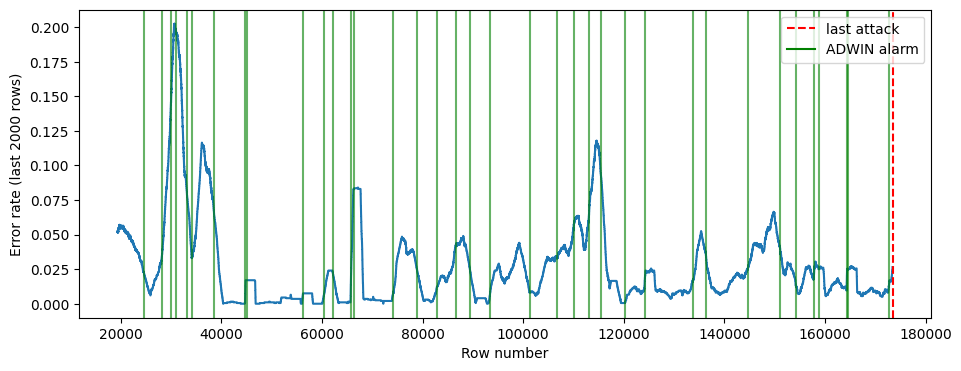

In [4]:
from river import drift

adwin = drift.ADWIN(delta=0.002)
alarms = []
for i, e in zip(idx, errors):
    out = adwin.update(int(e))
    detected = out[0] if isinstance(out, tuple) else adwin.drift_detected
    if detected:
        alarms.append(int(i))

active_alarms = [a for a in alarms if a <= last_attack]
tail_alarms = [a for a in alarms if a > last_attack]
print("Total alarms:", len(alarms))
print("Alarms inside the active window (row numbers):", active_alarms)
print("Alarms inside the normal-only tail:", len(tail_alarms), tail_alarms[:10])
n_act = last_attack + 1 - train_end
print("Error rate: first 20,000 rows after training:", round(errors[:20000].mean(), 4),
      "| rows 117,000-173,000:", round(errors[117000 - train_end:n_act].mean(), 4),
      "| tail:", round(errors[n_act:].mean(), 5))

roll = pd.Series(errors).rolling(2000).mean()
plt.figure(figsize=(11, 4))
plt.plot(idx[:n_act], roll[:n_act])
plt.axvline(last_attack, color="red", linestyle="--", label="last attack")
for a in active_alarms:
    plt.axvline(a, color="green", alpha=0.6)
plt.plot([], [], color="green", label="ADWIN alarm")
plt.xlabel("Row number")
plt.ylabel("Error rate (last 2000 rows)")
plt.legend()
plt.show()

## 5. ADWIN on each class separately, with UP/DOWN labels
Attack rows: a 1 is a missed attack. Normal rows: a 1 is a false alarm. UP = errors rising, DOWN = errors falling.

In [5]:
def run_adwin(values, rows, window):
    """Run ADWIN on one stream; label each alarm UP (errors rising) or DOWN (errors falling)."""
    adwin = drift.ADWIN(delta=0.002)
    found = []
    for k, (v, r) in enumerate(zip(values, rows)):
        out = adwin.update(int(v))
        detected = out[0] if isinstance(out, tuple) else adwin.drift_detected
        if detected and k >= 2 * window:
            recent = values[k - window + 1:k + 1].mean()
            before = values[k - 2 * window + 1:k - window + 1].mean()
            found.append((int(r), "UP" if recent > before else "DOWN"))
    return found

att = y == 1
miss_alarms = run_adwin(errors[att], idx[att], window=300)
nor = y == 0
fa_alarms = run_adwin(errors[nor], idx[nor], window=3000)

def summarize(name, alarms):
    up = [r for r, d in alarms if d == "UP" and r <= last_attack]
    down = [r for r, d in alarms if d == "DOWN" and r <= last_attack]
    tail = [r for r, d in alarms if r > last_attack]
    print(f"{name}: {len(alarms)} alarms | UP in active window: {len(up)} {up[:15]} "
          f"| DOWN in active window: {len(down)} | in tail: {len(tail)}")

summarize("Missed attacks (attack rows)", miss_alarms)
summarize("False alarms (normal rows)", fa_alarms)

print("\nMiss rate on attacks by period:")
for lo, hi in [(17344, 60000), (60000, 117000), (117000, last_attack + 1)]:
    m = att & (idx >= lo) & (idx < hi)
    print(f"  rows {lo}-{hi - 1}: {errors[m].mean():.3f}  ({int(m.sum())} attacks)")

Missed attacks (attack rows): 3 alarms | UP in active window: 2 [134791, 138408] | DOWN in active window: 1 | in tail: 0
False alarms (normal rows): 38 alarms | UP in active window: 27 [28141, 30047, 30922, 33236, 38455, 44723, 45024, 56143, 62351, 66336, 74089, 101216, 104819, 109846, 113131] | DOWN in active window: 10 | in tail: 1

Miss rate on attacks by period:
  rows 17344-59999: 0.018  (2699 attacks)
  rows 60000-116999: 0.007  (5719 attacks)
  rows 117000-173432: 0.089  (4558 attacks)


## 6. Does retraining help? (ungated periodic schedules, labels arrive immediately)
Exploratory: four hand-picked schedules, one run each. The 'drift zone' (row 117,000 onward) was chosen after looking at the data, so it is not an unbiased test region.

In [6]:
N = last_attack + 1                                   # the active window
X_raw = make_features(df.iloc[:N]).reindex(columns=columns, fill_value=0.0).to_numpy()
y_all = y_full[:N]

def fit_on(a, b):
    sc = StandardScaler().fit(X_raw[a:b])
    m = SGDClassifier(loss="log_loss", class_weight="balanced", random_state=42)
    m.fit(sc.transform(X_raw[a:b]), y_all[a:b])
    return sc, m

def run_periodic(period=None, window=20000, chunk=1000):
    """Retrain every `period` rows on the newest `window` rows (labels assumed to arrive immediately)."""
    sc, m = fit_on(0, train_end)
    preds_p = np.zeros(N, dtype=int)
    n_updates = 0
    for s in range(train_end, N, chunk):
        e = min(s + chunk, N)
        if period and s > train_end and (s - train_end) % period == 0:
            sc, m = fit_on(max(0, s - window), s)
            n_updates += 1
        preds_p[s:e] = m.predict(sc.transform(X_raw[s:e]))
    return preds_p, n_updates

def score(p_all, lo, hi):
    yy, pp = y_all[lo:hi], p_all[lo:hi]
    return (round(balanced_accuracy_score(yy, pp), 3), round(recall_score(yy, pp, pos_label=1), 3),
            round(recall_score(yy, pp, pos_label=0), 3))

configs = {
    "never update": dict(period=None),
    "every 10,000 rows, newest 20,000": dict(period=10000, window=20000),
    "every 40,000 rows, newest 20,000": dict(period=40000, window=20000),
    "every 10,000 rows, newest 50,000": dict(period=10000, window=50000),
}
rows = []
for name, kw in configs.items():
    p_all, nu = run_periodic(**kw)
    a1 = score(p_all, train_end, N)
    a2 = score(p_all, 117000, N)
    rows.append({"method": name, "updates": nu,
                 "ALL balanced_acc": a1[0], "ALL attack_recall": a1[1], "ALL normal_recall": a1[2],
                 "DRIFT-ZONE balanced_acc": a2[0], "DRIFT-ZONE attack_recall": a2[1], "DRIFT-ZONE normal_recall": a2[2]})
headroom = pd.DataFrame(rows)
display(headroom)

os.makedirs("/content/drive/MyDrive/DriftWise/results", exist_ok=True)
headroom.to_csv("/content/drive/MyDrive/DriftWise/results/real_data_periodic_headroom.csv", index=False)
print("Saved: real_data_periodic_headroom.csv")

,method,updates,ALL balanced_acc,ALL attack_recall,ALL normal_recall,DRIFT-ZONE balanced_acc,DRIFT-ZONE attack_recall,DRIFT-ZONE normal_recall
0,never update,0,0.968,0.962,0.974,0.949,0.911,0.987
1,"every 10,000 rows, newest 20,000",15,0.964,0.959,0.970,0.961,0.949,0.973
2,"every 40,000 rows, newest 20,000",3,0.922,0.875,0.969,0.978,0.983,0.972
3,"every 10,000 rows, newest 50,000",15,0.974,0.975,0.972,0.969,0.957,0.981


Saved: real_data_periodic_headroom.csv


In [7]:
import sys
import numpy as np, pandas as pd
from river import drift
sys.path.insert(0, "/content/drive/MyDrive/DriftWise/src")
from ega_gate import sequential_gate            # the sequential gate saved earlier in Drive

class AlarmMonitor:
    """Two ADWIN detectors: one on missed attacks, one on false alarms. Only UP alarms (errors rising) count."""
    def __init__(self):
        self.reset()
    def reset(self):
        self.det = {1: drift.ADWIN(delta=0.002), 0: drift.ADWIN(delta=0.002)}
        self.hist = {1: [], 0: []}
        self.win = {1: 300, 0: 3000}
    def update(self, yb, eb):
        up = False
        for cls in (1, 0):
            for e in eb[yb == cls]:
                h = self.hist[cls]
                h.append(int(e))
                out = self.det[cls].update(int(e))
                detected = out[0] if isinstance(out, tuple) else self.det[cls].drift_detected
                w = self.win[cls]
                if detected and len(h) >= 2 * w:
                    if np.mean(h[-w:]) > np.mean(h[-2 * w:-w]):
                        up = True
        return up

def run_real(method, patience=None, val_size=3000, gap=500, short=10000, long=30000,
             gate_every=1000, T=15000, every_alarm_window=20000, chunk=1000):
    """method = 'every_alarm' (retrain at each UP alarm) or 'ega' (gated). Labels arrive immediately."""
    sc, m = fit_on(0, train_end)
    preds_r = np.zeros(N, dtype=int)
    mon = AlarmMonitor()
    in_ep, alarm_t, look, n_acc, streak = False, None, 0, 0, 0
    updates, n_alarms = [], 0
    for s in range(train_end, N, chunk):
        e = min(s + chunk, N)
        pb = m.predict(sc.transform(X_raw[s:e]))
        preds_r[s:e] = pb
        t = e                                    # labels are known for rows before t
        fired = mon.update(y_all[s:e], (pb != y_all[s:e]).astype(int))

        if method == "every_alarm":
            if fired:
                n_alarms += 1
                sc, m = fit_on(max(0, t - every_alarm_window), t)
                updates.append(t)
                mon.reset()
            continue

        if (not in_ep) and fired:
            in_ep, alarm_t, look, n_acc, streak = True, t, 0, 0, 0
            n_alarms += 1
        if in_ep and (t - alarm_t) % gate_every == 0:
            look += 1
            te = t - val_size - gap
            Xv, yv = X_raw[t - val_size:t], y_all[t - val_size:t]
            p_cur = m.predict(sc.transform(Xv))
            best = None
            for w in (short, long):
                c_sc, c_m = fit_on(max(0, te - w), te)
                r = sequential_gate(yv, c_m.predict(c_sc.transform(Xv)), p_cur,
                                    look=look, alpha_total=0.05 / 2)
                if r["decision"] == "ACCEPT" and (best is None or r["est_balacc"] > best[2]["est_balacc"]):
                    best = (c_sc, c_m, r)
            if best is not None:
                sc, m = best[0], best[1]
                updates.append(t); n_acc += 1; streak = 0
                if patience is None:
                    in_ep = False; mon.reset()
            else:
                streak += 1
                if patience is not None and n_acc > 0 and streak >= patience:
                    in_ep = False; mon.reset()
                elif t - alarm_t >= T:
                    in_ep = False; mon.reset()
            if in_ep and t - alarm_t >= T:
                in_ep = False; mon.reset()
    return preds_r, updates, n_alarms

rows = []
def add_row(name, p_all, n_updates, first_update=None, n_alarms=None):
    a1, a2 = score(p_all, train_end, N), score(p_all, 117000, N)
    rows.append({"method": name, "alarms": n_alarms, "updates": n_updates,
                 "first update at row": first_update,
                 "ALL balanced_acc": a1[0], "ALL attack_recall": a1[1], "ALL normal_recall": a1[2],
                 "DRIFT-ZONE balanced_acc": a2[0], "DRIFT-ZONE attack_recall": a2[1], "DRIFT-ZONE normal_recall": a2[2]})

p, nu = run_periodic(period=None);                         add_row("never update", p, nu)
p, nu = run_periodic(period=10000, window=50000);          add_row("periodic: every 10,000 rows, newest 50,000", p, nu)
for name, kw in [("retrain at every UP alarm (newest 20,000)", dict(method="every_alarm")),
                 ("EGA, stop at first accept", dict(method="ega", patience=None)),
                 ("EGA v2, keep improving", dict(method="ega", patience=3))]:
    p, u, na = run_real(**kw)
    add_row(name, p, len(u), u[0] if u else None, na)

real_ega = pd.DataFrame(rows)
pd.set_option("display.width", 300, "display.max_columns", 20, "display.max_colwidth", None)
display(real_ega)
real_ega.to_csv("/content/drive/MyDrive/DriftWise/results/real_data_ega_vs_baselines.csv", index=False)
print("Saved: real_data_ega_vs_baselines.csv")

,method,alarms,updates,first update at row,ALL balanced_acc,ALL attack_recall,ALL normal_recall,DRIFT-ZONE balanced_acc,DRIFT-ZONE attack_recall,DRIFT-ZONE normal_recall
0,never update,NaN,0,NaN,0.968,0.962,0.974,0.949,0.911,0.987
1,"periodic: every 10,000 rows, newest 50,000",NaN,15,NaN,0.974,0.975,0.972,0.969,0.957,0.981
2,"retrain at every UP alarm (newest 20,000)",13.0,13,28344.0,0.966,0.961,0.972,0.953,0.933,0.973
3,"EGA, stop at first accept",10.0,8,32344.0,0.967,0.963,0.970,0.971,0.970,0.971
4,"EGA v2, keep improving",8.0,7,32344.0,0.973,0.977,0.970,0.970,0.969,0.971


Saved: real_data_ega_vs_baselines.csv


In [8]:
import numpy as np, pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDClassifier

SEED = 42
def fit_on(a, b):                      # same as before, but the model's random seed is now a variable
    sc = StandardScaler().fit(X_raw[a:b])
    m = SGDClassifier(loss="log_loss", class_weight="balanced", random_state=SEED)
    m.fit(sc.transform(X_raw[a:b]), y_all[a:b])
    return sc, m

SEEDS = [42, 7, 123]
rows = []
for SEED in SEEDS:
    print("running with random seed", SEED, "...")
    runs = {}
    p, nu = run_periodic(period=None);                      runs["never update"] = (p, nu)
    p, nu = run_periodic(period=10000, window=50000);       runs["periodic (every 10,000, newest 50,000)"] = (p, nu)
    for name, kw in [("retrain at every UP alarm (newest 20,000)", dict(method="every_alarm", every_alarm_window=20000)),
                     ("retrain at every UP alarm (newest 30,000)", dict(method="every_alarm", every_alarm_window=30000)),
                     ("EGA v2, keep improving", dict(method="ega", patience=3))]:
        p, u, na = run_real(**kw)
        runs[name] = (p, len(u))
    for name, (p, nu) in runs.items():
        a1, a2 = score(p, train_end, N), score(p, 117000, N)
        rows.append({"seed": SEED, "method": name, "updates": nu,
                     "ALL balanced_acc": a1[0], "DRIFT balanced_acc": a2[0], "DRIFT attack_recall": a2[1]})
stab = pd.DataFrame(rows)

pd.set_option("display.width", 300, "display.max_columns", 20, "display.max_colwidth", None)
print("\nMean and standard deviation over the random seeds:")
display(stab.groupby("method")[["updates", "ALL balanced_acc", "DRIFT balanced_acc", "DRIFT attack_recall"]]
        .agg(["mean", "std"]).round(3))

print("\nEGA v2 minus each other method, DRIFT-zone balanced accuracy, one value per seed:")
ega = stab[stab.method == "EGA v2, keep improving"].set_index("seed")["DRIFT balanced_acc"]
for name in stab.method.unique():
    if name.startswith("EGA"):
        continue
    other = stab[stab.method == name].set_index("seed")["DRIFT balanced_acc"]
    d = (ega - other).round(3)
    print(f"  vs {name:45s} {d.tolist()}  mean {d.mean():+.3f}")

stab.to_csv("/content/drive/MyDrive/DriftWise/results/real_data_stability.csv", index=False)
print("\nSaved: real_data_stability.csv")

running with random seed 42 ...
running with random seed 7 ...
running with random seed 123 ...

Mean and standard deviation over the random seeds:


updates        ALL balanced_acc        DRIFT balanced_acc        DRIFT attack_recall       
                                             mean    std             mean    std               mean    std                mean    std
method                                                                                                                               
EGA v2, keep improving                      7.000  0.000            0.971  0.006              0.968  0.004               0.963  0.007
never update                                0.000  0.000            0.964  0.006              0.938  0.017               0.888  0.035
periodic (every 10,000, newest 50,000)     15.000  0.000            0.972  0.005              0.969  0.002               0.958  0.004
retrain at every UP alarm (newest 20,000)  14.000  1.000            0.964  0.002              0.957  0.005               0.941  0.010
retrain at every UP alarm (newest 30,000)  13.667  1.155            0.968  0.004              0.962  0.008               0.944  0.015


EGA v2 minus each other method, DRIFT-zone balanced accuracy, one value per seed:
  vs never update                                  [0.021, 0.053, 0.017]  mean +0.030
  vs periodic (every 10,000, newest 50,000)        [0.001, 0.003, -0.008]  mean -0.001
  vs retrain at every UP alarm (newest 20,000)     [0.017, 0.009, 0.007]  mean +0.011
  vs retrain at every UP alarm (newest 30,000)     [0.017, 0.007, -0.006]  mean +0.006

Saved: real_data_stability.csv
